# Spline on the sphere

For data observed over the globe, a standard smooth of latitude and longitude treats
them as coordinates on a flat rectangle. This ignores that longitudes $-180$ and $180$
are the same meridian, and that each pole is a single point, so the fitted surface need
not join up across these boundaries.

The [`SplineOnSphere`][pymgcv.basis_functions.SplineOnSphere] basis instead defines the
smooth on the sphere itself. It takes exactly two variables: latitude in $[-90, 90]$
followed by longitude in $[-180, 180]$, both in degrees. In this example, we simulate
data from a bump centered at latitude 30 and longitude 150, close enough to the
$\pm 180$ meridian that it wraps around to the other edge of the map.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pymgcv.basis_functions import SplineOnSphere
from pymgcv.gam import GAM
from pymgcv.terms import S


def f(lat, lon):
    """Bump centered at latitude 30 and longitude 150, in degrees."""
    lat, lon = np.radians(lat), np.radians(lon)
    lat0, lon0 = np.radians(30), np.radians(150)
    cos_dist = np.sin(lat) * np.sin(lat0)
    cos_dist += np.cos(lat) * np.cos(lat0) * np.cos(lon - lon0)
    return 2 * np.exp(4 * (cos_dist - 1))


rng = np.random.default_rng(1)
n = 200
lat = np.degrees(np.arcsin(rng.uniform(-1, 1, n)))  # Uniform over the sphere
lon = rng.uniform(-180, 180, n)
y = f(lat, lon) + rng.normal(scale=0.1, size=n)
data = pd.DataFrame({"lat": lat, "lon": lon, "y": y})

We fit a standard thin plate spline and a spline on the sphere, and compare their
predictions over the globe with the true function.

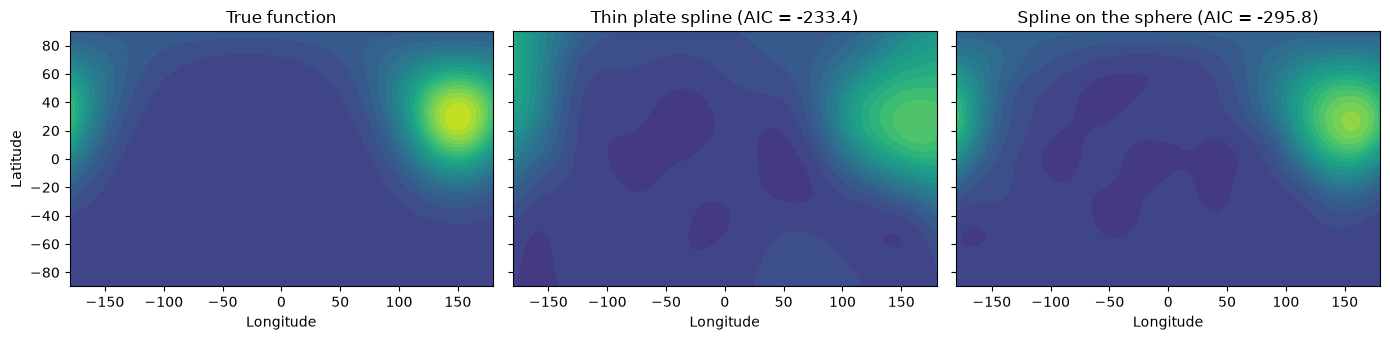

In [2]:
# Force re run
models = {
    "Thin plate spline": GAM({"y": S("lat", "lon")}),
    "Spline on the sphere": GAM({"y": S("lat", "lon", bs=SplineOnSphere())}),
}

lon_grid, lat_grid = np.meshgrid(np.linspace(-180, 180, 181), np.linspace(-90, 90, 91))
grid = pd.DataFrame({"lat": lat_grid.ravel(), "lon": lon_grid.ravel()})
surfaces = {"True function": f(lat_grid, lon_grid)}
for name, gam in models.items():
    gam.fit(data)
    pred = gam.predict(grid)["y"].reshape(lat_grid.shape)
    surfaces[f"{name} (AIC = {gam.aic():.1f})"] = pred

levels = np.linspace(-0.5, 2.2, 28)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, (name, surface) in zip(axes, surfaces.items(), strict=True):
    ax.contourf(lon_grid, lat_grid, surface, levels=levels, extend="both")
    ax.set_title(name)
    ax.set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
fig.tight_layout()
plt.show()

The thin plate spline treats the edges of the map as boundaries, so the data on one
side of the $\pm 180$ meridian does not inform the fit on the other side. It flattens
the bump and shifts its peak towards the edge, misses most of the part that wraps
around to the left edge, and its predictions do not match across the meridian. Along
the top edge, which is the single point at the north pole, its predictions also vary
with longitude. The spline on the sphere recovers the bump in the right place,
including the part on the left edge, joins up across the meridian, and has a lower
AIC.

!!! tip

    The `m` argument of [`SplineOnSphere`][pymgcv.basis_functions.SplineOnSphere]
    sets the order of the penalty. The default `m=0` uses a second order spline on the
    sphere, while `m=-1` uses a
    [`DuchonSpline`][pymgcv.basis_functions.DuchonSpline] on the sphere.